# Assignment 9: Streamflow prediction from rainfall with neural networks

Predicting how much water will be in a river in a few days' time is the core of flood
forecasting, reservoir operation and drought management. The physical problem is
**rainfall-runoff**: rain falls on a catchment, some evaporates, some soaks into the soil,
some runs off into the channel, and the river responds hours to days later. That response is
strongly **nonlinear** (the same 20 mm of rain produces a trickle on dry ground in August and a flood on saturated ground in March) and it depends on the *history* of the catchment,
not just today's weather.

That combination makes it a natural neural network problem, and it is one of the areas where
machine learning has most clearly outperformed traditional conceptual hydrological models.

You will use two real public datasets:

- **USGS streamflow**: daily mean discharge measured at gauging stations, the backbone of
  US water resource monitoring.
- **Daymet**: daily gridded precipitation and temperature for North America, from Oak Ridge
  National Laboratory.

Both are free and need no API key. You will build a **regional** model: one network trained
on six catchments at once, rather than a separate model per river.

Answer each numbered question in the empty cell below it.

In [35]:
import os

os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"

In [36]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## Load the data

Six gauged catchments, chosen to be small enough that a single Daymet grid cell is a
reasonable summary of the rain falling on them, and to span a range of climates from
northern Maine to the southern Appalachians. `drainage_sq_mi` is the catchment area.

This downloads twelve time series and takes a couple of minutes.

In [37]:
BASINS = {
    # site_no: (latitude, longitude, drainage area in square miles, name)
    "02177000": (34.8138, -83.3064,  207, "Chattooga River, GA"),
    "01547700": (41.0595, -77.6058, 44.1, "Marsh Creek, PA"),
    "01013500": (47.2375, -68.5828,  870, "Fish River, ME"),
    "01543500": (41.3173, -78.1031,  685, "Sinnemahoning Creek, PA"),
    "02143040": (35.6640, -81.2140, 62.0, "Henry Fork, NC"),
    "03164000": (36.6473, -80.9790, 1141, "New River, VA"),
}
START, END = "1995-01-01", "2020-12-31"


def load_basin(site, lat, lon, area, name):
    """Daily discharge from USGS plus daily weather from Daymet, joined on date."""
    # USGS daily values, parameter 00060 = discharge in cubic feet per second.
    url = (f"https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites={site}"
           f"&startDT={START}&endDT={END}&parameterCd=00060&siteStatus=all")
    text = urllib.request.urlopen(url).read().decode()
    rows = [line.split("\t") for line in text.splitlines() if line.startswith("USGS")]
    flow = pd.DataFrame(rows).iloc[:, [2, 3]]
    flow.columns = ["date", "discharge_cfs"]
    flow["date"] = pd.to_datetime(flow["date"])
    flow["discharge_cfs"] = pd.to_numeric(flow["discharge_cfs"], errors="coerce")

    # Daymet single-pixel extraction at the gauge location.
    url = (f"https://daymet.ornl.gov/single-pixel/api/data?lat={lat}&lon={lon}"
           f"&vars=prcp,tmax,tmin&start={START}&end={END}")
    met = pd.read_csv(io.StringIO(urllib.request.urlopen(url).read().decode()), skiprows=6)
    met.columns = ["year", "yday", "prcp", "tmax", "tmin"]
    met["date"] = (pd.to_datetime(met["year"].astype(str), format="%Y")
                   + pd.to_timedelta(met["yday"] - 1, unit="D"))

    df = met.merge(flow, on="date", how="inner").sort_values("date").reset_index(drop=True)
    df["site"] = site
    df["name"] = name
    df["area_sq_mi"] = area
    df["lat"] = lat
    df["lon"] = lon
    return df


frames = []
for site, (lat, lon, area, name) in BASINS.items():
    d = load_basin(site, lat, lon, area, name)
    print(f"{name:<26} {len(d):>6,} days  "
          f"{d.date.min().date()} to {d.date.max().date()}")
    frames.append(d)

raw = pd.concat(frames, ignore_index=True)
print(f"\ntotal: {len(raw):,} basin-days across {raw.site.nunique()} catchments")
raw.head()

Chattooga River, GA         9,490 days  1995-01-01 to 2020-12-30
Marsh Creek, PA             9,490 days  1995-01-01 to 2020-12-30
Fish River, ME              9,490 days  1995-01-01 to 2020-12-30
Sinnemahoning Creek, PA     9,490 days  1995-01-01 to 2020-12-30
Henry Fork, NC              9,490 days  1995-01-01 to 2020-12-30
New River, VA               9,490 days  1995-01-01 to 2020-12-30

total: 56,940 basin-days across 6 catchments


,year,yday,prcp,tmax,tmin,date,discharge_cfs,site,name,area_sq_mi,lat,lon
0,1995,1,0.0,13.42,3.80,1995-01-01,643.0,02177000,"Chattooga River, GA",207.0,34.8138,-83.3064
1,1995,2,0.0,9.22,-2.67,1995-01-02,588.0,02177000,"Chattooga River, GA",207.0,34.8138,-83.3064
2,1995,3,0.0,7.03,-4.34,1995-01-03,564.0,02177000,"Chattooga River, GA",207.0,34.8138,-83.3064
3,1995,4,0.0,5.93,-5.19,1995-01-04,557.0,02177000,"Chattooga River, GA",207.0,34.8138,-83.3064
4,1995,5,0.0,4.55,-10.18,1995-01-05,540.0,02177000,"Chattooga River, GA",207.0,34.8138,-83.3064


```{admonition} Note on Daymet's calendar
:class: note
Daymet uses a 365-day year and omits 31 December in leap years, so the inner join above
silently drops those days. That is fine here, but it is the kind of thing worth noticing
when you join two climate datasets: a silent loss of six days per two decades is easy to
miss and not always harmless.
```

## Part 1: Explore the data

1. Plot the discharge time series for one catchment over a five-year window, with a
logarithmic y-axis. In one sentence, how do the rises compare with the falls?

<Axes: title={'center': 'Chattooga River, GA discharge (cfs, logarithmic y-axis), 2016-2021'}, xlabel='Time', ylabel='Discharge (cfs)'>

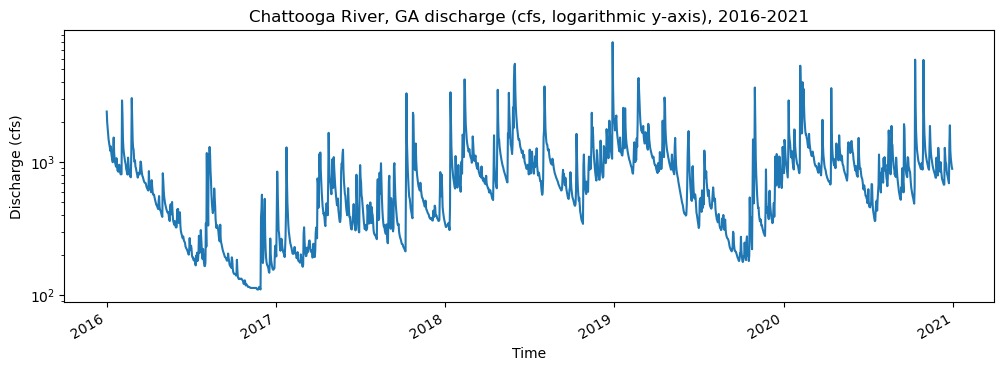

In [243]:
catchment_chattooga_5yr = raw[(raw["name"]=="Chattooga River, GA") & (raw["date"].between("2016-01-01","2020-12-31"))]

catchment_chattooga_5yr.plot(x='date',y='discharge_cfs', logy=True,figsize =(12,4),legend = False, xlabel = "Time", ylabel="Discharge (cfs)", title="Chattooga River, GA discharge (cfs, logarithmic y-axis), 2016-2021")

_For the Chattooga River, GA catchment, the rises (the left side of each spike) appear to be steep and short because the discharge rises rapidly during a storm, while the falls (right side of each spike) are longer, indicating it takes a while for the water to drain after a storm._

2. Plot the distribution of daily discharge for all catchments together, first on a linear
scale and then after a $\log(1+x)$ transform. In one sentence, which is easier to model with a
squared-error loss, and why?

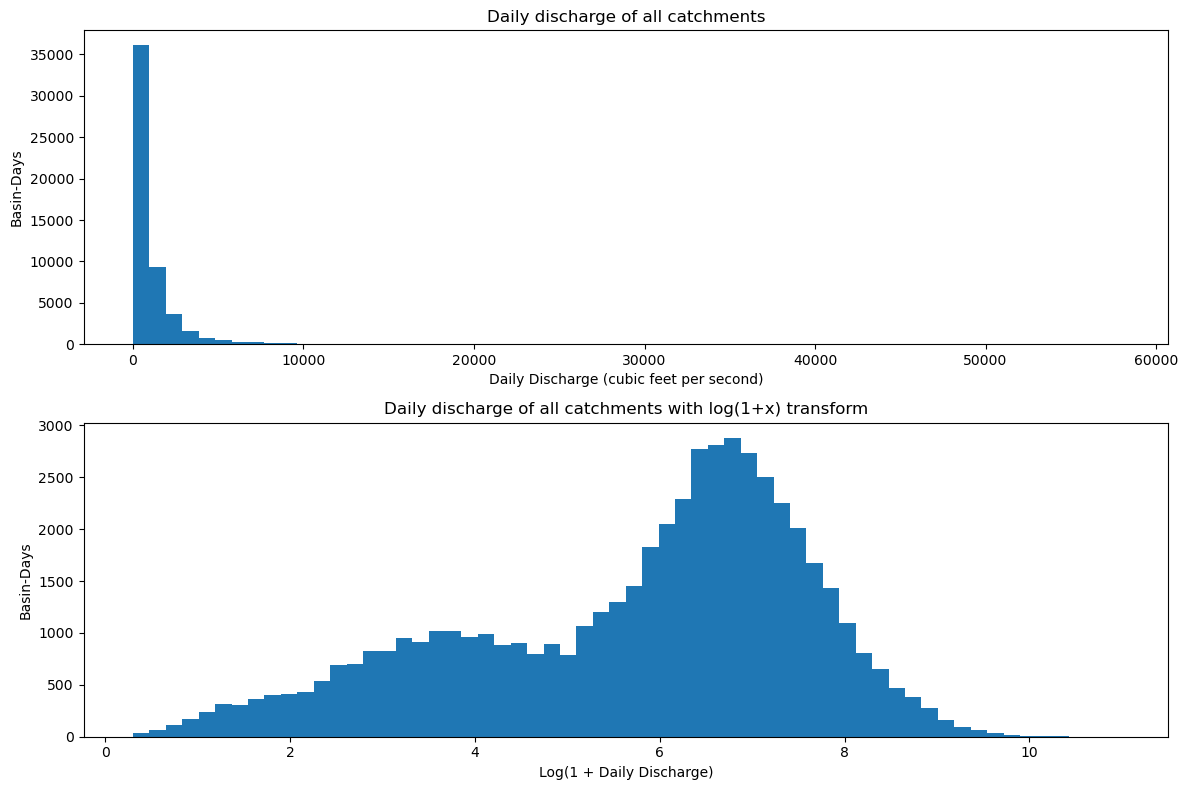

In [235]:
fig, (ax1,ax2) = plt.subplots(2, 1, figsize=(12, 8))

ax1.hist(raw['discharge_cfs'],bins=60)
ax1.set_title("Daily discharge of all catchments")
ax1.set_xlabel("Daily Discharge (cubic feet per second)")
ax1.set_ylabel("Basin-Days")

raw["log1+x_discharge"] = np.log1p(raw["discharge_cfs"])

ax2.hist(raw["log1+x_discharge"],bins=60)
ax2.set_title("Daily discharge of all catchments with log(1+x) transform")
ax2.set_xlabel("Log(1 + Daily Discharge)")
ax2.set_ylabel("Basin-Days")

plt.tight_layout()
plt.show()

_It is easier to model with a squared-error loss using the $\log(1+x)$ transform than using the linear scale because the log transform compresses the most extreme right-skewed values so that rare large spikes in daily discharge, like values of 50,000 cfs or more, do not produce disproportionately large squared errors, allowing the model to weight relative errors more evenly across high and low discharges._

3. Make a scatter plot of same-day discharge against same-day precipitation for one
catchment, and compute the correlation. It will be much weaker than you might expect.
In one sentence, give one physical reason why today's rainfall alone is a poor predictor of
today's flow.

In [ ]:
catchment_chattooga = raw[(raw["name"]=="Chattooga River, GA")]
plt.scatter(catchment_chattooga['prcp'],catchment_chattooga['discharge_cfs'], s=10, alpha = 0.7)
r = catchment_chattooga['prcp'].corr(catchment_chattooga['discharge_cfs'])
print(f"Correlation: {r:.3f}")
plt.xlabel("Chattooga River, GA Same-Day Precipitation (mm)")
plt.ylabel("Chattooga River, GA Same-Day Discharge (cfs)")
plt.title("Chattooga River, GA Same-Day Precipitation vs Same-Day Discharge")

_Today's rainfall is a poor predictor of today's flow because rainwater takes time, likely several days, to travel across the catchment and discharge out of the gauge, and the current day's discharge is influenced by runoff from prior days' storms, resulting in a very weak correlation (0.173) between same-day precipitation and same-day discharge._

4. Catchments differ enormously in size, so their discharges are not comparable. The New
River drains 26 times the area of Marsh Creek. Create a column `logQ` holding
$\log(1 + Q/A)$, where $Q$ is discharge in cfs and $A$ is drainage area in square miles.
Plot the distribution of `logQ` for each catchment on shared axes and confirm that they now
overlap.

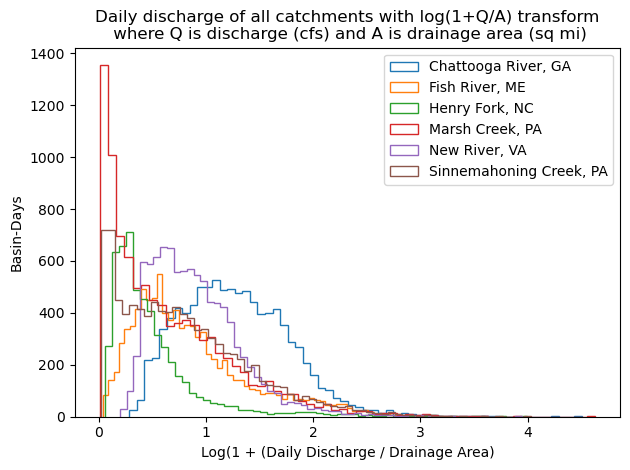

In [244]:
raw['logQ'] = np.log1p((raw["discharge_cfs"]/raw["area_sq_mi"]))

fig, ax = plt.subplots()

#label = BASINS[site][3]

for catchment_name, catchment_df in raw.groupby("name"):
    ax.hist(catchment_df["logQ"].dropna(),bins=60,histtype = "step",label=catchment_name)

ax.set_title("Daily discharge of all catchments with log(1+Q/A) transform\n where Q is discharge (cfs) and A is drainage area (sq mi)")
ax.legend()
ax.set_xlabel("Log(1 + (Daily Discharge / Drainage Area)")
ax.set_ylabel("Basin-Days")
plt.tight_layout()
plt.show()

## Part 2: Build the features

A network given only today's weather cannot know whether the ground is already saturated.
The catchment's *memory* has to be supplied explicitly, as features describing the recent
past.

5. Working **within each catchment separately** (use `groupby("site")` so that lags and
rolling totals never run from one catchment's record into the next), construct:

- `prcp_lag1` through `prcp_lag10`: precipitation on each of the previous ten days
- `prcp_sum3`, `prcp_sum7`, `prcp_sum14`, `prcp_sum30`, `prcp_sum90`: rolling
  precipitation totals, which act as proxies for how wet the catchment already is
- `tmean_7` and `tmean_30`, rolling mean temperature, a proxy for evaporative demand and
  for whether precipitation is falling as snow
- `doy_sin` and `doy_cos`, the day of year encoded as a pair of sinusoids

In [211]:
#prcp_lag1 through prcp_lag10: precipitation on each of the previous ten days

gb_prcp = raw.groupby("site")["prcp"]

for i in range(1,11):
    raw[f"prcp_lag{i}"] = gb_prcp.shift(i)

In [212]:
# prcp_sum3, prcp_sum7, prcp_sum14, prcp_sum30, prcp_sum90: rolling precipitation totals, which act as proxies for how wet the catchment already is

prcp_sum_list = [3,7,14,30,90]

for i in prcp_sum_list:
    raw[f"prcp_sum{i}"] = raw.groupby("site")["prcp_lag1"].rolling(i).sum().reset_index(level=0, drop=True)

In [99]:
# tmean_7 and tmean_30, rolling mean temperature, a proxy for evaporative demand and for whether precipitation is falling as snow

raw["tmean"] = (raw["tmax"] + raw["tmin"])/2
raw["tmean_lag1"] = raw.groupby("site")["tmean"].shift(1)

prcp_sum_list = [7,30]

for i in prcp_sum_list:
    raw[f"tmean_{i}"] = raw.groupby("site")["tmean_lag1"].rolling(i).mean().reset_index(level=0, drop=True)
print(raw["tmean_7"].iloc[6:8])
print(raw["tmean_30"].iloc[29:31])

6         NaN
7    1.827143
Name: tmean_7, dtype: float64
29       NaN
30    5.2125
Name: tmean_30, dtype: float64


In [101]:
# doy_sin and doy_cos, the day of year encoded as a pair of sinusoids

raw["doy"] = raw["date"].dt.dayofyear

raw["doy_sin"] = np.sin(raw["doy"] * 2 * np.pi / (365.25))
raw["doy_cos"] = np.cos(raw["doy"] * 2 * np.pi / (365.25))

raw[["date", "doy", "doy_sin", "doy_cos"]]

,date,doy,doy_sin,doy_cos
0,1995-01-01,1,0.017202,0.999852
1,1995-01-02,2,0.034398,0.999408
2,1995-01-03,3,0.051584,0.998669
3,1995-01-04,4,0.068755,0.997634
4,1995-01-05,5,0.085906,0.996303
...,...,...,...,...
56935,2020-12-26,361,-0.073045,0.997329
56936,2020-12-27,362,-0.055879,0.998438
56937,2020-12-28,363,-0.038696,0.999251
56938,2020-12-29,364,-0.021501,0.999769


In [246]:
raw[["date", "prcp_lag1", "prcp_lag5", "prcp_lag10", "prcp_sum3", "prcp_sum7", "prcp_sum14", "prcp_sum30", "prcp_sum90", "tmean_7","tmean_30","doy","doy_sin", "doy_cos"]]

,date,prcp_lag1,prcp_lag5,prcp_lag10,prcp_sum3,prcp_sum7,prcp_sum14,prcp_sum30,prcp_sum90,tmean_7,tmean_30,doy,doy_sin,doy_cos
0,1995-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0.017202,0.999852
1,1995-01-02,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,0.034398,0.999408
2,1995-01-03,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,0.051584,0.998669
3,1995-01-04,0.0,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,4,0.068755,0.997634
4,1995-01-05,0.0,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,5,0.085906,0.996303
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56935,2020-12-26,0.0,0.00,19.52,29.95,29.95,84.29,124.53,451.55,1.041429,3.049667,361,-0.073045,0.997329
56936,2020-12-27,0.0,0.00,0.00,28.34,29.95,84.29,124.53,451.55,0.369286,2.480833,362,-0.055879,0.998438
56937,2020-12-28,0.0,1.61,0.00,0.00,29.95,63.38,124.53,445.11,-0.135714,2.120667,363,-0.038696,0.999251
56938,2020-12-29,0.0,28.34,0.00,0.00,29.95,53.49,124.53,410.79,-0.723571,1.861833,364,-0.021501,0.999769


6. Also within each catchment, construct `logQ_lag0` through `logQ_lag3`, the
area-normalized log discharge today and on the three previous days. These are the single
most informative features you will build: rivers have long memories.

Then create the **target**, `target`, as `logQ` **three days in the future**. This makes the
task a three-day-ahead forecast.

In [105]:
for i in range(4):
    raw[f"logQ_lag{i}"] = raw.groupby("site")["logQ"].shift(i)

raw["target"] = raw.groupby("site")["logQ"].shift(-3)

raw

,year,yday,prcp,tmax,tmin,date,discharge_cfs,site,name,area_sq_mi,...,tmean_30,tmean_lag1,doy,doy_sin,doy_cos,logQ_lag0,logQ_lag1,logQ_lag2,logQ_lag3,target
0,1995,1,0.0,13.42,3.80,1995-01-01,643.0,02177000,"Chattooga River, GA",207.0,...,NaN,NaN,1,0.017202,0.999852,1.412518,NaN,NaN,NaN,1.305849
1,1995,2,0.0,9.22,-2.67,1995-01-02,588.0,02177000,"Chattooga River, GA",207.0,...,NaN,8.610,2,0.034398,0.999408,1.345623,1.412518,NaN,NaN,1.283346
2,1995,3,0.0,7.03,-4.34,1995-01-03,564.0,02177000,"Chattooga River, GA",207.0,...,NaN,3.275,3,0.051584,0.998669,1.314970,1.345623,1.412518,NaN,1.364315
3,1995,4,0.0,5.93,-5.19,1995-01-04,557.0,02177000,"Chattooga River, GA",207.0,...,NaN,1.345,4,0.068755,0.997634,1.305849,1.314970,1.345623,1.412518,2.115615
4,1995,5,0.0,4.55,-10.18,1995-01-05,540.0,02177000,"Chattooga River, GA",207.0,...,NaN,0.370,5,0.085906,0.996303,1.283346,1.305849,1.314970,1.345623,1.689258
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56935,2020,361,0.0,1.12,-12.85,2020-12-26,3480.0,03164000,"New River, VA",1141.0,...,3.049667,-7.305,361,-0.073045,0.997329,1.398706,1.526513,1.157603,1.129676,1.224188
56936,2020,362,0.0,7.22,-10.97,2020-12-27,2860.0,03164000,"New River, VA",1141.0,...,2.480833,-5.865,362,-0.055879,0.998438,1.254639,1.398706,1.526513,1.157603,1.200725
56937,2020,363,0.0,9.06,-7.97,2020-12-28,2800.0,03164000,"New River, VA",1141.0,...,2.120667,-1.875,363,-0.038696,0.999251,1.239529,1.254639,1.398706,1.526513,NaN
56938,2020,364,0.0,7.70,-2.27,2020-12-29,2740.0,03164000,"New River, VA",1141.0,...,1.861833,0.545,364,-0.021501,0.999769,1.224188,1.239529,1.254639,1.398706,NaN


7. Drop rows containing NaN (the lags and rolling windows leave gaps at the start of each
catchment's record, and the target leaves gaps at the end). Assemble the feature matrix `X`
from all the engineered features plus `area_sq_mi`, `lat` and `lon`, and the target vector
`y`. Report the shapes and the number of features.

In [108]:
print(raw.columns.tolist())

['year', 'yday', 'prcp', 'tmax', 'tmin', 'date', 'discharge_cfs', 'site', 'name', 'area_sq_mi', 'lat', 'lon', 'log1+x_discharge', 'logQ', 'prcp_lag1', 'prcp_lag2', 'prcp_lag3', 'prcp_lag4', 'prcp_lag5', 'prcp_lag6', 'prcp_lag7', 'prcp_lag8', 'prcp_lag9', 'prcp_lag10', 'prcp_sum3', 'prcp_sum7', 'prcp_sum14', 'prcp_sum30', 'prcp_sum90', 'tmean', 'tmean_7', 'tmean_30', 'tmean_lag1', 'doy', 'doy_sin', 'doy_cos', 'logQ_lag0', 'logQ_lag1', 'logQ_lag2', 'logQ_lag3', 'target']


In [248]:
df = raw.dropna()

feat_columns = ['area_sq_mi', 'lat', 'lon', 'prcp_lag1', 'prcp_lag2', 
    'prcp_lag3', 'prcp_lag4', 'prcp_lag5', 'prcp_lag6', 
    'prcp_lag7', 'prcp_lag8', 'prcp_lag9', 'prcp_lag10', 
    'prcp_sum3', 'prcp_sum7', 'prcp_sum14', 'prcp_sum30', 
    'prcp_sum90','tmean_7', 'tmean_30','doy_sin', 'doy_cos', 
    'logQ_lag0', 'logQ_lag1', 'logQ_lag2', 'logQ_lag3']

X = df[feat_columns]
y = df["target"]
print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
print("Number of features:", X.shape[1])

Feature matrix: (52353, 26)
Target vector: (52353,)
Number of features: 26


## Part 3: Splitting and scaling

8. Split the data by date: train on everything before 2014,
validate on 2014–2016, and test on 2017 onwards. Report the size of each split.

In [127]:
train_mask =  df["year"] < 2014
val_mask = df["year"].between(2014, 2016)
test_mask = df["year"] >= 2017

X_train = X[train_mask]
y_train = y[train_mask]
X_valid = X[val_mask]
y_valid = y[val_mask]
X_test = X[test_mask]
y_test = y[test_mask]

print(f"X train shape: {X_train.shape}")
print(f"X val shape: {X_val.shape}")
print(f"X test shape: {X_test.shape}")

X train shape: (37537, 26)
X val shape: (6531, 26)
X test shape: (8285, 26)


9. Scale the features with `StandardScaler`. Fit the scaler on the training set,
then transform all three sets with it.

In [130]:
x_scaler = StandardScaler().fit(X_train)

def scale_x(df):  return x_scaler.transform(df)

Xs_train, Xs_valid, Xs_test = scale_x(X_train), scale_x(X_valid), scale_x(X_test)

## Part 4: Train a neural network

10. Using `tensorflow`, build a fully connected network that takes the feature matrix as
input and has three hidden `Dense` layers of 128, 64 and 32 units with `ReLU` activation,
followed by a final `Dense` layer with a single output and no activation.

In [133]:
tf.keras.backend.clear_session()
tf.random.set_seed(42)

n_features = Xs_train.shape[1]
model = tf.keras.Sequential([
    tf.keras.Input(shape=[n_features]),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

11. Print the model summary. How many trainable parameters does it have?

In [134]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               3456      
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 dense_2 (Dense)             (None, 32)                2080      
                                                                 
 dense_3 (Dense)             (None, 1)                 33        
                                                                 
Total params: 13,825
Trainable params: 13,825
Non-trainable params: 0
_________________________________________________________________


_The model has 13,825 trainable parameters._

12. Compile the model with MSE loss and the `Adam` optimizer, including root mean squared error as a metric.

In [140]:
model.compile(loss="mse",
              optimizer=tf.keras.optimizers.Adam(),
              metrics=[tf.keras.metrics.RootMeanSquaredError()])

13. Train the model for up to 200 epochs using the validation set, with an `EarlyStopping`
callback (`patience=20`, `restore_best_weights=True`). Report the epoch it stopped at.

In [141]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                              restore_best_weights=True)
history = model.fit(Xs_train, y_train, epochs=200,
                    validation_data=(Xs_valid, y_valid),
                    callbacks=[early_stop], verbose=0)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Stopped after {len(history.epoch)} epochs and kept the weights from epoch {best_epoch}.")

Stopped after 27 epochs and kept the weights from epoch 7.


14. Plot the training and validation loss against epoch number.

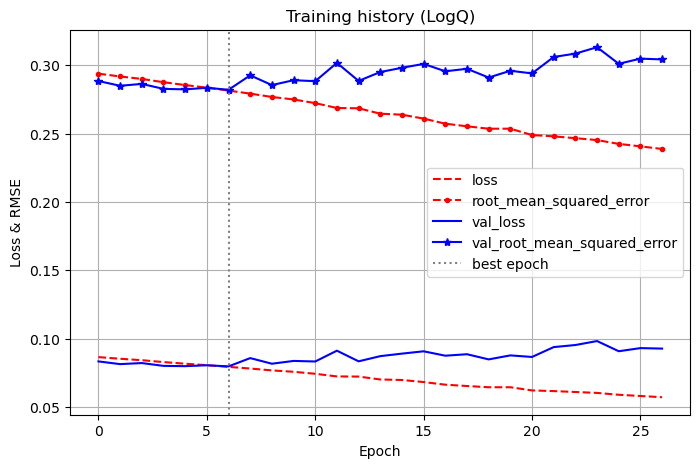

In [251]:
ax = pd.DataFrame(history.history).plot(
    figsize=(8, 5), grid=True, xlabel="Epoch", ylabel="Loss & RMSE",
    style=["r--", "r--.", "b-", "b-*"])
ax.axvline(best_epoch - 1, color="gray", linestyle=":", label="best epoch")
ax.legend()
plt.title("Training history (LogQ)")
plt.show()

15. Save the trained model.

In [144]:
model.save("streamflow_model.keras")

## Part 5: Evaluate

16. Evaluate the model on the **test** set and report the MSE and RMSE. Then compute the
$R^2$ between predicted and observed `logQ`.

In [172]:
test_mse, test_rmse = model.evaluate(Xs_test, y_test, verbose=0)
print(f"Test MSE: {test_mse:.3f}")
print(f"Test RMSE: {test_rmse:.3f}")

Test MSE: 0.125
Test RMSE: 0.354


In [180]:
y_pred_network = model.predict(Xs_test, verbose=0).ravel()

ss_res = np.sum((y_test.to_numpy() - y_pred_network) ** 2)
ss_tot = np.sum((y_test.to_numpy() - y_test.mean()) ** 2)
r2_network = 1 - ss_res / ss_tot
print(f"Neural Network test R^2 between predicted and observed logQ: {r2_network:.3f}")

Neural Network test R^2 between predicted and observed logQ: 0.679


17. A score means nothing without a baseline. Compare your network against two:

- **Persistence**: predict that the flow in three days equals today's flow
  (`logQ_lag0`). This is what a forecaster with no model at all would say, and on a river
  it is a genuinely strong prediction.
- **Linear regression**: the same features, fitted with `LinearRegression`.

Report $R^2$ for all three on the test set, in one table.

In [181]:
#persistence
y_pred_pers = X_test["logQ_lag0"].to_numpy()

res_pers = np.sum((y_test.to_numpy() - y_pred_pers) ** 2)
tot_pers = np.sum((y_test.to_numpy() - y_test.mean()) ** 2)
r2_pers = 1 - res_pers / tot_pers
print(f"Persistence test R^2 between predicted logQ_lag0 and observed logQ: {r2_pers:.3f}")

Persistence test R^2 between predicted logQ_lag0 and observed logQ: 0.584


In [182]:
#linear regression
reg = LinearRegression()
reg.fit(Xs_train, y_train)
pred = reg.predict(Xs_test)

res_linear = np.sum((y_test.to_numpy() - pred) ** 2)
tot_linear = np.sum((y_test.to_numpy() - y_test.mean()) ** 2)
r2_linear = 1 - res_linear / tot_linear
print(f"Linear Regression test R^2: {r2_linear:.3f}")

Linear Regression test R^2: 0.663


In [183]:
results_df = pd.DataFrame([{"Method": "Neural Network", "Test R^2": r2_network},
                           {"Method": "Persistence", "Test R^2": r2_pers},
                           {"Method": "Linear Regression", "Test R^2": r2_linear}])
results_rounded = results_df.round({"Test R^2": 3})
results_rounded

,Method,Test R^2
0,Neural Network,0.679
1,Persistence,0.584
2,Linear Regression,0.663


18. Make a scatter plot of predicted against observed `logQ` for the test set, with a 1:1
line. In one sentence, where in the range does the model do worst?

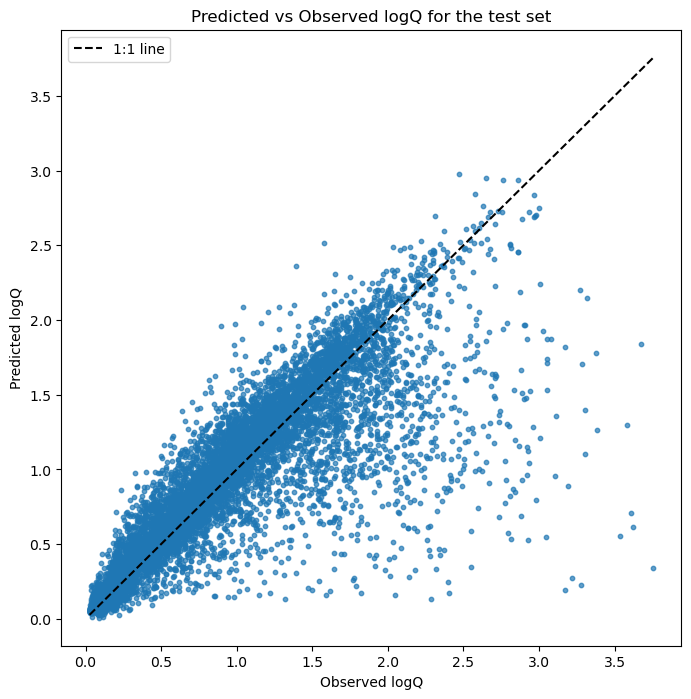

In [194]:
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_network, s = 10, alpha=0.7)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "k--", label="1:1 line")
plt.xlabel("Observed logQ")
plt.ylabel("Predicted logQ")
plt.title("Predicted vs Observed logQ for the test set")
plt.legend()
plt.show()

_The model does the worst in predicting observed logQ values between 1.5 and 3.5 (high-flow events), with it underpredicting many of those points as being in the range of 0.0 to 2.0._

19. Plot the observed and predicted hydrograph for one catchment over a single test year, so
that the two curves can be compared day by day. In one sentence, does the model capture the
timing and the size of the peaks?

In [215]:
df_test = df[test_mask]

ch_2020_mask = ((df_test["name"] == "Chattooga River, GA") & (df_test["year"] == 2020)).to_numpy()

df_test_ch_2020 = df_test[ch_2020_mask]
y_test_ch_2020 = y_test[ch_2020_mask]
y_pred_ch_2020 = y_pred_network[ch_2020_mask]

print(f"Chattooga River, GA 2020 df test shape: {df_test_ch_2020.shape}")
print(f"Chattooga River, GA 2020 y-test shape: {y_test_ch_2020.shape}")
print(f"Chattooga River, GA 2020 y-pred shape: {y_pred_ch_2020.shape}")

dates_ch_2020 = pd.to_datetime(df_test_ch_2020["date"])

Chattooga River, GA 2020 df test shape: (362, 41)
Chattooga River, GA 2020 y-test shape: (362,)
Chattooga River, GA 2020 y-pred shape: (362,)


In [237]:
df_test_ch_2020

,year,yday,prcp,tmax,tmin,date,discharge_cfs,site,name,area_sq_mi,...,tmean_30,tmean_lag1,doy,doy_sin,doy_cos,logQ_lag0,logQ_lag1,logQ_lag2,logQ_lag3,target
9125,2020,1,0.00,12.79,0.02,2020-01-01,889.0,02177000,"Chattooga River, GA",207.0,...,8.115833,7.410,1,0.017202,0.999852,1.666704,1.827350,1.985157,1.527945,2.024199
9126,2020,2,36.33,10.24,0.90,2020-01-02,826.0,02177000,"Chattooga River, GA",207.0,...,8.143500,6.405,2,0.034398,0.999408,1.607504,1.666704,1.827350,1.985157,1.872916
9127,2020,3,17.66,14.98,4.61,2020-01-03,1470.0,02177000,"Chattooga River, GA",207.0,...,8.155833,5.570,3,0.051584,0.998669,2.092043,1.607504,1.666704,1.827350,1.771425
9128,2020,4,1.36,13.90,7.09,2020-01-04,1360.0,02177000,"Chattooga River, GA",207.0,...,8.259167,9.795,4,0.068755,0.997634,2.024199,2.092043,1.607504,1.666704,1.712186
9129,2020,5,0.00,11.71,-1.07,2020-01-05,1140.0,02177000,"Chattooga River, GA",207.0,...,8.286500,10.495,5,0.085906,0.996303,1.872916,2.024199,2.092043,1.607504,1.644563
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9482,2020,358,14.92,12.14,1.68,2020-12-23,693.0,02177000,"Chattooga River, GA",207.0,...,7.133500,8.645,358,-0.124395,0.992233,1.469676,1.501390,1.537335,1.569018,1.930611
9483,2020,359,43.15,11.73,0.28,2020-12-24,1390.0,02177000,"Chattooga River, GA",207.0,...,6.959333,6.910,359,-0.107308,0.994226,2.043163,1.469676,1.501390,1.537335,1.819550
9484,2020,360,0.00,-3.25,-6.48,2020-12-25,1890.0,02177000,"Chattooga River, GA",207.0,...,6.947167,6.005,360,-0.090190,0.995925,2.315544,2.043163,1.469676,1.501390,1.754019
9485,2020,361,0.00,6.91,-9.05,2020-12-26,1220.0,02177000,"Chattooga River, GA",207.0,...,6.528833,-4.865,361,-0.073045,0.997329,1.930611,2.315544,2.043163,1.469676,1.698139


In [236]:
df_test

,year,yday,prcp,tmax,tmin,date,discharge_cfs,site,name,area_sq_mi,...,tmean_30,tmean_lag1,doy,doy_sin,doy_cos,logQ_lag0,logQ_lag1,logQ_lag2,logQ_lag3,target
8030,2017,1,21.48,9.75,-0.85,2017-01-01,195.0,02177000,"Chattooga River, GA",207.0,...,7.049167,4.620,1,0.017202,0.999852,0.663733,0.758591,0.709914,0.569915,1.346880
8031,2017,2,24.33,13.09,5.61,2017-01-02,389.0,02177000,"Chattooga River, GA",207.0,...,6.910667,4.450,2,0.034398,0.999408,1.057522,0.663733,0.758591,0.709914,1.033752
8032,2017,3,0.00,16.04,9.46,2017-01-03,848.0,02177000,"Chattooga River, GA",207.0,...,6.973500,9.350,3,0.051584,0.998669,1.628577,1.057522,0.663733,0.758591,0.905606
8033,2017,4,0.00,12.18,6.46,2017-01-04,589.0,02177000,"Chattooga River, GA",207.0,...,7.187000,12.750,4,0.068755,0.997634,1.346880,1.628577,1.057522,0.663733,0.877881
8034,2017,5,0.00,9.09,-2.22,2017-01-05,375.0,02177000,"Chattooga River, GA",207.0,...,7.366500,9.320,5,0.085906,0.996303,1.033752,1.346880,1.628577,1.057522,0.802846
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56932,2020,358,1.61,8.81,-4.82,2020-12-23,2390.0,03164000,"New River, VA",1141.0,...,3.602333,3.920,358,-0.124395,0.992233,1.129676,1.173992,1.213828,1.247113,1.398706
56933,2020,359,28.34,10.45,-3.41,2020-12-24,2490.0,03164000,"New River, VA",1141.0,...,3.472500,1.995,359,-0.107308,0.994226,1.157603,1.129676,1.173992,1.213828,1.254639
56934,2020,360,0.00,-5.50,-9.11,2020-12-25,4110.0,03164000,"New River, VA",1141.0,...,3.478000,3.520,360,-0.090190,0.995925,1.526513,1.157603,1.129676,1.173992,1.239529
56935,2020,361,0.00,1.12,-12.85,2020-12-26,3480.0,03164000,"New River, VA",1141.0,...,3.049667,-7.305,361,-0.073045,0.997329,1.398706,1.526513,1.157603,1.129676,1.224188


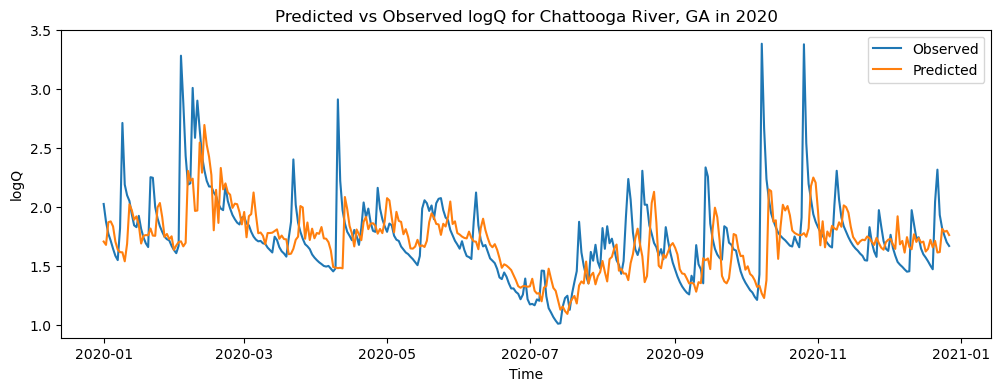

In [220]:
plt.figure(figsize=(12, 4))

plt.plot(dates_ch_2020,y_test_ch_2020, label = "Observed")
plt.plot(dates_ch_2020,y_pred_ch_2020, label = "Predicted")
plt.title("Predicted vs Observed logQ for Chattooga River, GA in 2020")
plt.xlabel("Time")
plt.ylabel("logQ")
plt.legend()
plt.show()

_No, the model captures neither the timing nor the size of the peaks well because the predicted peaks are much smaller than the observed peaks and the predicted storm spikes lag behind the observed storm spikes by a few days._